In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Scikit-learn imported successfully!")

Scikit-learn imported successfully!


In [11]:
df = pd.read_csv("C:/Users/APARNA/Downloads/soil_fertility_classification_1000.csv")
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1000, 20)


,Sample_ID,Source_Calibration,State,District,Soil_Type,Crop,pH,Electrical_Conductivity_dS_m,Organic_Carbon_g_kg,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Sulphur_mg_kg,Zinc_mg_kg,Boron_mg_kg,Iron_mg_kg,Manganese_mg_kg,Copper_mg_kg,Fertility_Score,Fertility_Class
0,SFC-0001,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Lucknow,Alluvial,Cotton,6.91,0.150,12.08,169.90,32.32,54.05,15.46,1.34,1.13,16.65,7.20,1.00,47.15,Medium Fertility
1,SFC-0002,Indian laboratory soil dataset calibrated exte...,Maharashtra,Nashik,Red,Cotton,6.61,0.424,10.85,170.47,31.70,126.62,11.17,0.87,1.39,15.67,6.15,1.36,46.47,Medium Fertility
2,SFC-0003,Indian laboratory soil dataset calibrated exte...,Karnataka,Mysuru,Loamy,Pulses,7.52,0.596,5.51,130.75,32.14,381.20,10.98,0.51,0.83,21.16,5.31,0.69,39.27,Low Fertility
3,SFC-0004,Indian laboratory soil dataset calibrated exte...,Punjab,Ludhiana,Clay Loam,Rice,7.03,0.257,9.48,202.66,49.68,77.23,20.79,0.76,1.60,38.51,9.07,0.60,59.38,Medium Fertility
4,SFC-0005,Indian laboratory soil datasets (AgriNet/Krish...,Uttar Pradesh,Bareilly,Loamy,Vegetables,7.17,0.282,15.65,189.12,24.58,213.50,17.32,1.35,0.47,25.92,17.15,1.20,61.00,Medium Fertility


In [12]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTarget Class Distribution:")
print(df['Fertility_Class'].value_counts())

Missing values in each column:
Sample_ID                       0
Source_Calibration              0
State                           0
District                        0
Soil_Type                       0
Crop                            0
pH                              0
Electrical_Conductivity_dS_m    0
Organic_Carbon_g_kg             0
Available_N_kg_ha               0
Available_P_kg_ha               0
Available_K_kg_ha               0
Sulphur_mg_kg                   0
Zinc_mg_kg                      0
Boron_mg_kg                     0
Iron_mg_kg                      0
Manganese_mg_kg                 0
Copper_mg_kg                    0
Fertility_Score                 0
Fertility_Class                 0
dtype: int64

Target Class Distribution:
Fertility_Class
Medium Fertility    596
Low Fertility       319
High Fertility       85
Name: count, dtype: int64


In [13]:
num_features = [
    'pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg',
    'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha',
    'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg',
    'Manganese_mg_kg', 'Copper_mg_kg'
]


X_num = df[num_features]
X_cat = pd.get_dummies(df['Soil_Type'], prefix='Soil', drop_first=True)


X = pd.concat([X_num, X_cat], axis=1)
y = df['Fertility_Class']

print("Features Shape (X):", X.shape)
print("Features List:\n", list(X.columns))


Features Shape (X): (1000, 18)
Features List:
 ['pH', 'Electrical_Conductivity_dS_m', 'Organic_Carbon_g_kg', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg', 'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg', 'Soil_Black', 'Soil_Clay Loam', 'Soil_Lateritic', 'Soil_Loamy', 'Soil_Red', 'Soil_Sandy Loam']


C:\Users\APARNA\AppData\Local\Temp\ipykernel_26432\2770755456.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Fertility_Class', data=df, order=['Low Fertility', 'Medium Fertility', 'High Fertility'], palette='Set2')


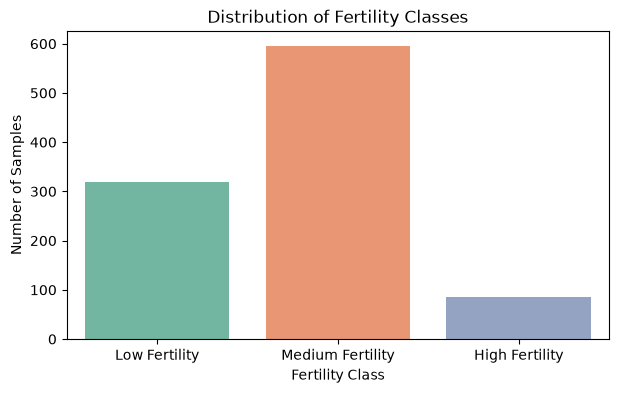

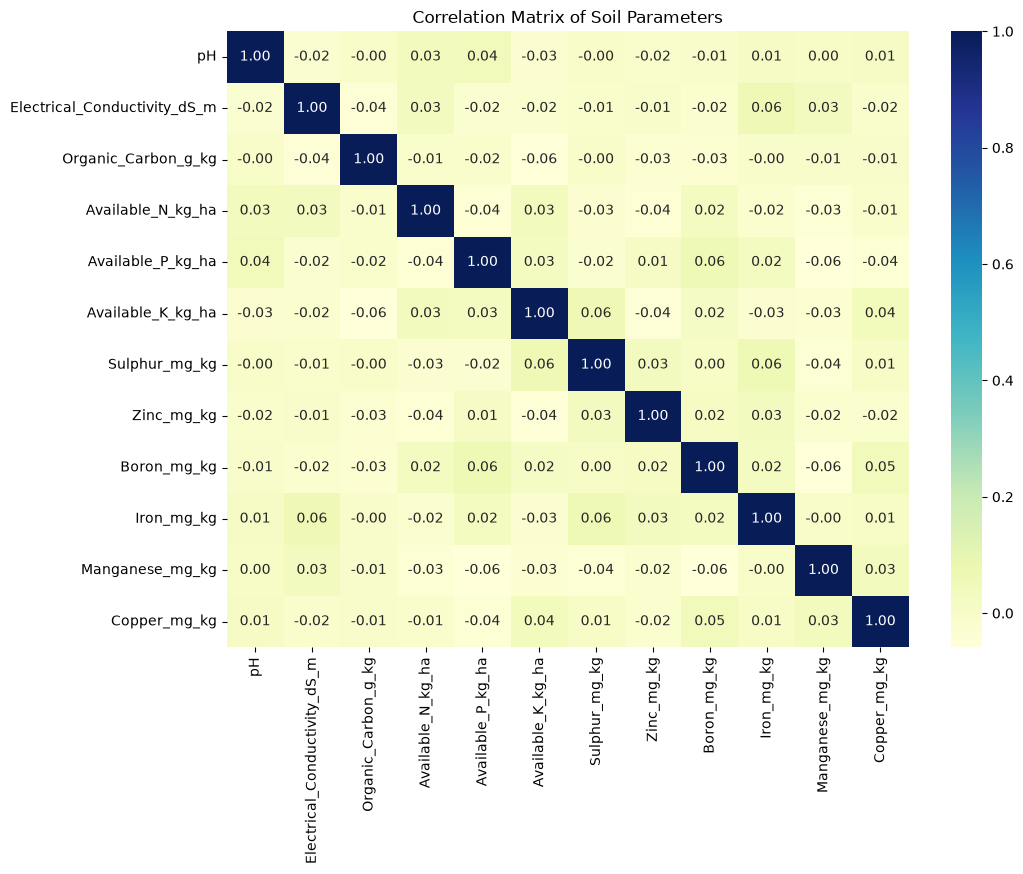

In [14]:
plt.figure(figsize=(7, 4))
sns.countplot(x='Fertility_Class', data=df, order=['Low Fertility', 'Medium Fertility', 'High Fertility'], palette='Set2')
plt.title("Distribution of Fertility Classes")
plt.xlabel("Fertility Class")
plt.ylabel("Number of Samples")
plt.show()
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_features].corr(), annot=True, fmt=".2f", cmap='YlGnBu')
plt.title("Correlation Matrix of Soil Parameters")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_features] = scaler.fit_transform(X_train[num_features])
X_test_scaled[num_features] = scaler.transform(X_test[num_features])

print("Training Samples Count:", X_train_scaled.shape[0])
print("Testing Samples Count:", X_test_scaled.shape[0])

Training Samples Count: 800
Testing Samples Count: 200


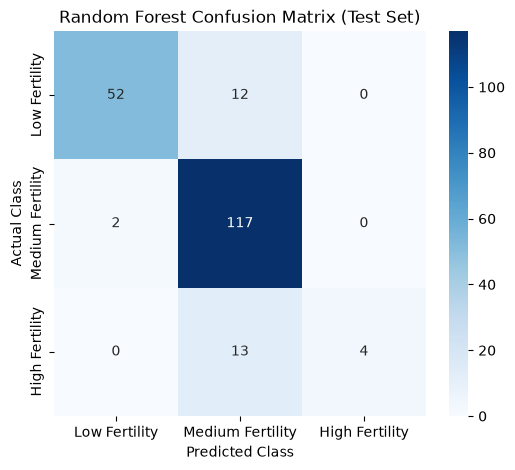

Detailed Classification Report:

                  precision    recall  f1-score   support

  High Fertility       1.00      0.24      0.38        17
   Low Fertility       0.96      0.81      0.88        64
Medium Fertility       0.82      0.98      0.90       119

        accuracy                           0.86       200
       macro avg       0.93      0.68      0.72       200
    weighted avg       0.88      0.86      0.85       200



In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
best_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
best_model.fit(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)
class_labels = ['Low Fertility', 'Medium Fertility', 'High Fertility']
cm = confusion_matrix(y_test, y_pred_best, labels=class_labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest Confusion Matrix (Test Set)")
plt.show()

print("Detailed Classification Report:\n")
print(classification_report(y_test, y_pred_best))

C:\Users\APARNA\AppData\Local\Temp\ipykernel_26432\3909669851.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Parameter', data=feature_importance_df.head(10), palette='crest')


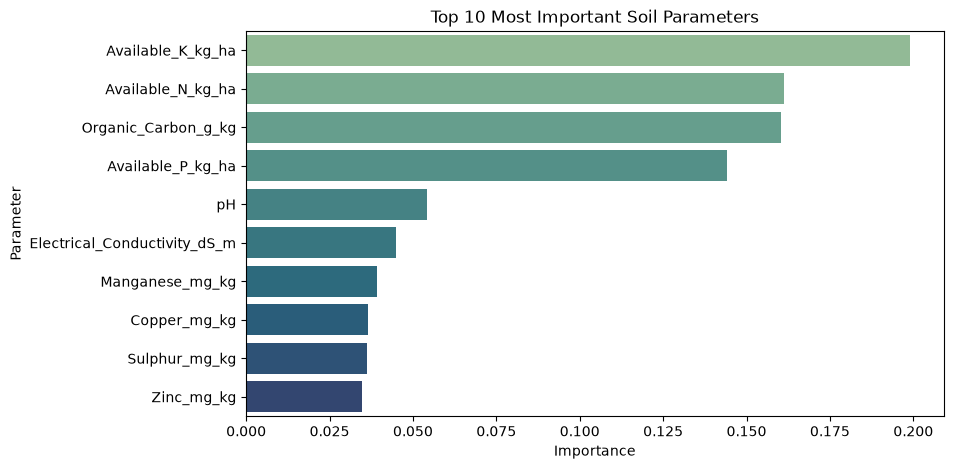

,Parameter,Importance
5,Available_K_kg_ha,0.199141
3,Available_N_kg_ha,0.161219
2,Organic_Carbon_g_kg,0.160227
4,Available_P_kg_ha,0.144228
0,pH,0.054066
1,Electrical_Conductivity_dS_m,0.044799
10,Manganese_mg_kg,0.039325
11,Copper_mg_kg,0.036566
6,Sulphur_mg_kg,0.036277
7,Zinc_mg_kg,0.034851


In [20]:
from sklearn.ensemble import RandomForestClassifier
best_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
best_model.fit(X_train_scaled, y_train)
importances = best_model.feature_importances_
feature_names = X_train_scaled.columns

feature_importance_df = pd.DataFrame({
    'Parameter': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)
plt.figure(figsize=(9, 5))
sns.barplot(x='Importance', y='Parameter', data=feature_importance_df.head(10), palette='crest')
plt.title("Top 10 Most Important Soil Parameters")
plt.show()

feature_importance_df.head(10)

In [21]:
new_sample = {
    'pH': 7.15,
    'Electrical_Conductivity_dS_m': 0.32,
    'Organic_Carbon_g_kg': 13.5,
    'Available_N_kg_ha': 240.0,
    'Available_P_kg_ha': 65.0,
    'Available_K_kg_ha': 280.0,
    'Sulphur_mg_kg': 15.5,
    'Zinc_mg_kg': 1.2,
    'Boron_mg_kg': 0.8,
    'Iron_mg_kg': 21.0,
    'Manganese_mg_kg': 9.2,
    'Copper_mg_kg': 0.75,
    'Soil_Type': 'Alluvial'
}
new_sample_df = pd.DataFrame([new_sample])
new_sample_df[num_features] = scaler.transform(new_sample_df[num_features])
new_sample_encoded = pd.get_dummies(new_sample_df)
new_sample_aligned = new_sample_encoded.reindex(columns=X_train_scaled.columns, fill_value=0)
predicted_class = best_model.predict(new_sample_aligned)[0]
confidence = best_model.predict_proba(new_sample_aligned)[0]

print("=== Prediction Result for New Soil Sample ===")
print(f"Predicted Fertility Class: {predicted_class}\n")
for cls, prob in zip(best_model.classes_, confidence):
    print(f"Confidence for {cls}: {prob * 100:.2f}%")

=== Prediction Result for New Soil Sample ===
Predicted Fertility Class: High Fertility

Confidence for High Fertility: 58.17%
Confidence for Low Fertility: 0.46%
Confidence for Medium Fertility: 41.37%


In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


df = pd.read_csv(
  "C:/Users/APARNA/Downloads/soil_fertility_classification_1000.csv"
)


num_features = [
    'pH', 'Electrical_Conductivity_dS_m',
    'Organic_Carbon_g_kg', 'Available_N_kg_ha',
    'Available_P_kg_ha', 'Available_K_kg_ha',
    'Sulphur_mg_kg', 'Zinc_mg_kg', 'Boron_mg_kg',
    'Iron_mg_kg', 'Manganese_mg_kg', 'Copper_mg_kg'
]


X = df.drop(columns=[
    'Sample_ID', 'Source_Calibration', 'Fertility_Score',
    'Fertility_Class'
])

y = df['Fertility_Class']


X = pd.get_dummies(X)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_features] = scaler.fit_transform(
    X_train[num_features]
)

X_test_scaled[num_features] = scaler.transform(
    X_test[num_features]
)


best_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42
)

best_model.fit(X_train_scaled, y_train)


y_pred_best = best_model.predict(X_test_scaled)

print("Model trained successfully!")
print("Training samples:", len(y_train))
print("Testing samples:", len(y_test))

Model trained successfully!
Training samples: 800
Testing samples: 200


     SOIL FERTILITY ML MODEL EVALUATION
Accuracy  : 80.50%
Precision : 0.7681
Recall    : 0.8050
F1-Score  : 0.7648

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

  High Fertility     0.0000    0.0000    0.0000        17
   Low Fertility     1.0000    0.6562    0.7925        64
Medium Fertility     0.7532    1.0000    0.8592       119

        accuracy                         0.8050       200
       macro avg     0.5844    0.5521    0.5506       200
    weighted avg     0.7681    0.8050    0.7648       200


CONFUSION MATRIX
                          Predicted: Low Fertility  \
Actual: Low Fertility                           42   
Actual: Medium Fertility                         0   
Actual: High Fertility                           0   

                          Predicted: Medium Fertility  \
Actual: Low Fertility                              22   
Actual: Medium Fertility                          119   
Actual: High Fertility                        

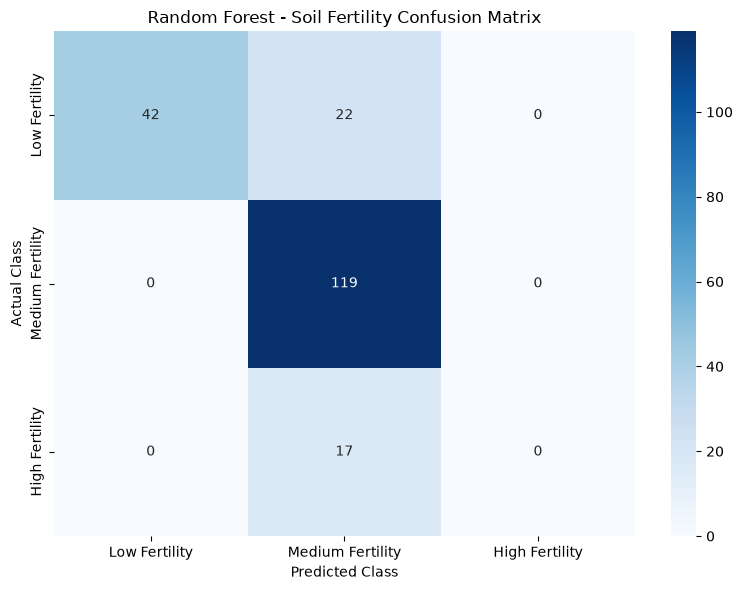

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


accuracy = accuracy_score(y_test, y_pred_best)

precision = precision_score(
    y_test, y_pred_best,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test, y_pred_best,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred_best,
    average='weighted',
    zero_division=0
)


print("=" * 45)
print("     SOIL FERTILITY ML MODEL EVALUATION")
print("=" * 45)

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")


print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0,
    digits=4
))


class_labels = [
    'Low Fertility',
    'Medium Fertility',
    'High Fertility'
]

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=class_labels
)

print("\nCONFUSION MATRIX")
print(pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels]
))


plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Random Forest - Soil Fertility Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()